[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C5_NB10_first_whole_brain_model.ipynb)

# Day 2 · Chapter 5 · Notebook 10 — A first whole-brain model (hands-on)

> **Your task.** Put one Hopf oscillator in every brain region, wire them with the connectome of NB09, and find the
> **distance to the bifurcation $a$** and the **global coupling $G$** that best reproduce the measured FC.
> Work in pairs, about 30 minutes. Solutions are at the end (hidden code, results shown): look only after trying.

In [1]:
# @title Setup: connectome, measured FC and BOLD (the data of NB09)
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import connectome
sc, fc, labels = connectome.load_hcp(weights="counts", normalize="rowsum", homotopic=0.5)   # human, 100 regions
bold_data = np.load("../data/empirical/fmri_ds000228_schaefer100.npz")["ts"]               # measured BOLD, 10 people
net = np.array([l.split("_")[2] for l in labels])                  # resting-state network of each region
NETS = ["Vis", "SomMot", "DorsAttn", "SalVentAttn", "Limbic", "Cont", "Default"]
order = np.concatenate([np.where(net == n)[0] for n in NETS])     # regions sorted by network, for display
u = np.triu_indices(100, 1)
similarity = lambda A, B: np.corrcoef(A[u], B[u])[0, 1]           # how alike two matrices are (1 = identical pattern)

def show_matrix(ax, M, title, **kw):
    ax.imshow(M[np.ix_(order, order)], **kw); ax.set_title(title); ax.set(xticks=[], yticks=[])
    sizes = [np.sum(net == n) for n in NETS]
    for e in np.cumsum(sizes)[:-1] - 0.5: ax.axhline(e, c="k", lw=0.4); ax.axvline(e, c="k", lw=0.4)
    mids = np.cumsum([0] + sizes); ax.set_yticks((mids[:-1] + mids[1:]) / 2 - 0.5, NETS, fontsize=7)

print(f"wiring alone vs measured FC: similarity {similarity(np.log1p(sc), fc):.2f}  <- the number to beat")

wiring alone vs measured FC: similarity 0.32  <- the number to beat


## 1. The model

> **Gist.** Each region is the simplest system with a Hopf bifurcation (NB08), slowed down to the pace of BOLD (one
> cycle in about 20 s), plus noise; regions are pulled towards their connected neighbours. Three knobs:
> * $a$, the **distance to the bifurcation**: $a<0$ damped oscillation kept alive by noise, $a>0$ self-sustained rhythm;
> * $\sigma$, the **noise**;
> * $G$, the **global coupling**.

`simulate(a, G, sigma)` returns 20 minutes of BOLD-like signals; `fc_similarity(a, G)` runs it twice and compares the
model FC with the measured FC. The code is short: click on the cell to read it.

<details><summary>Equation (for the curious)</summary>

$$\dot z_j=(a+i\omega)z_j-|z_j|^2z_j+G\sum_k W_{jk}(z_k-z_j)+\sigma\xi_j,\qquad \text{BOLD}_j\approx\mathrm{Re}\,z_j$$

$z_j$ is a complex number (amplitude and phase of region $j$), $\omega=2\pi\cdot0.05$ Hz, $\xi_j$ white noise,
$W$ the connectome. Without coupling this is the Stuart–Landau equation, the normal form of the Hopf bifurcation. This
is the model of Deco et al. (2017).
</details>

In [2]:
# @title The whole-brain simulator: a Hopf oscillator in every region, coupled through the connectome
def simulate(a, G, sigma=0.02, minutes=20, seed=0, f=0.05, dt=0.1, TR=2.0):
    # returns time (s) and BOLD-like signals (time x regions), sampled every TR
    rng = np.random.default_rng(seed)
    N = len(sc); strength = sc.sum(1); omega = 2 * np.pi * f
    z = 0.1 * (rng.standard_normal(N) + 1j * rng.standard_normal(N))         # random start
    every, n_skip = int(TR / dt), int(60 / dt)                                # sample every TR, skip the first minute
    out = []
    for k in range(n_skip + int(minutes * 60 / dt)):
        local = (a + 1j * omega) * z - np.abs(z) ** 2 * z                      # the region itself (Hopf normal form)
        coupling = G * (sc @ z - strength * z)                                 # pulled towards connected regions
        noise = sigma * np.sqrt(dt) * (rng.standard_normal(N) + 1j * rng.standard_normal(N))
        z = z + dt * (local + coupling) + noise                                # one Euler step
        if k >= n_skip and (k - n_skip) % every == every - 1:
            out.append(z.real)
    x = np.array(out)
    return np.arange(len(x)) * TR, x

def fc_similarity(a, G, sigma=0.02, runs=2):
    # model FC (average of a few 20-minute runs) and its similarity to the measured FC
    M = np.mean([np.corrcoef(simulate(a, G, sigma, seed=s)[1].T) for s in range(runs)], axis=0)
    return similarity(M, fc), M

t, x = simulate(a=-0.02, G=1.0)
print(f"{x.shape[0]} time points x {x.shape[1]} regions; one run takes well under a second")

600 time points x 100 regions; one run takes well under a second


## 2. Hands-on: find the working point (about 30 minutes)

Edit the cells marked `# your code`, run them, and **write down your answer** to each question before moving on.

### Step 1. One region alone ($G=0$)

**Add values to `a_values`** (between −1 and +0.3). The black trace is one region of a real recording.

**Question 1.** For which $a$ does the model look most like real BOLD? Compare the speed and regularity of the
fluctuations, not their size (every trace is rescaled).

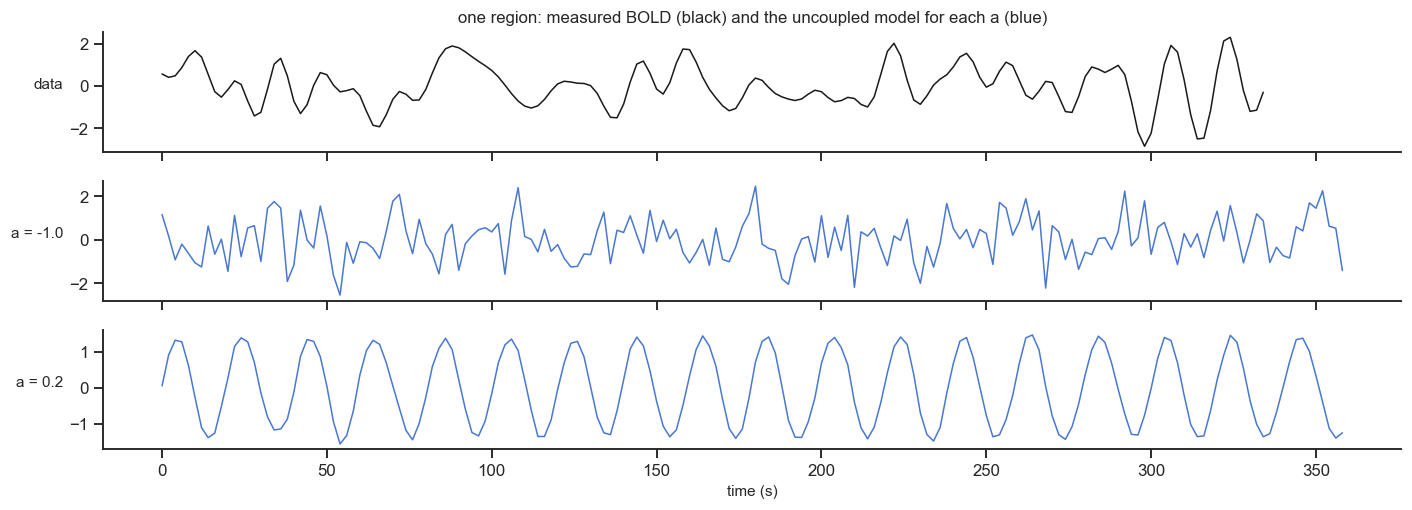

In [3]:
# your code: add values of a (distance to the bifurcation), e.g. -0.5, -0.1, -0.02, 0.05
a_values = [-1.0, 0.2]
region = 10

fig, ax = plt.subplots(len(a_values) + 1, 1, figsize=(13, 1.6 * (len(a_values) + 1)), sharex=True)
y = bold_data[0][:, region]; ax[0].plot(np.arange(len(y)) * 2.0, y / y.std(), "k", lw=1); ax[0].set_ylabel("data", rotation=0, ha="right")
ax[0].set_title("one region: measured BOLD (black) and the uncoupled model for each a (blue)")
for a_, a in zip(ax[1:], a_values):
    t, x = simulate(a, G=0.0, minutes=6)
    a_.plot(t, x[:, region] / x[:, region].std(), lw=1); a_.set_ylabel(f"a = {a}", rotation=0, ha="right")
ax[-1].set_xlabel("time (s)"); plt.tight_layout(); plt.show()

### Step 2. Noise

**Change `sigma_values`** and read the printed size of the fluctuations, below ($a=-0.5$) and above ($a=+0.2$) the
bifurcation.

**Question 2.** Below the bifurcation, what does more noise change? And above it?

In [4]:
# your code: change the noise values, e.g. 0.005, 0.05, 0.1
sigma_values = [0.01, 0.02]
for a in [-0.5, 0.2]:
    for sigma in sigma_values:
        t, x = simulate(a, G=0.0, sigma=sigma, minutes=6)
        print(f"a = {a:5}  sigma = {sigma:5}:  size of fluctuations {x.std():.3f}")

a =  -0.5  sigma =  0.01:  size of fluctuations 0.010
a =  -0.5  sigma =  0.02:  size of fluctuations 0.020
a =   0.2  sigma =  0.01:  size of fluctuations 0.320
a =   0.2  sigma =  0.02:  size of fluctuations 0.320


### Step 3. Couple the regions

**Change `a` and `G`** and rerun: compare the model FC with the measured FC.

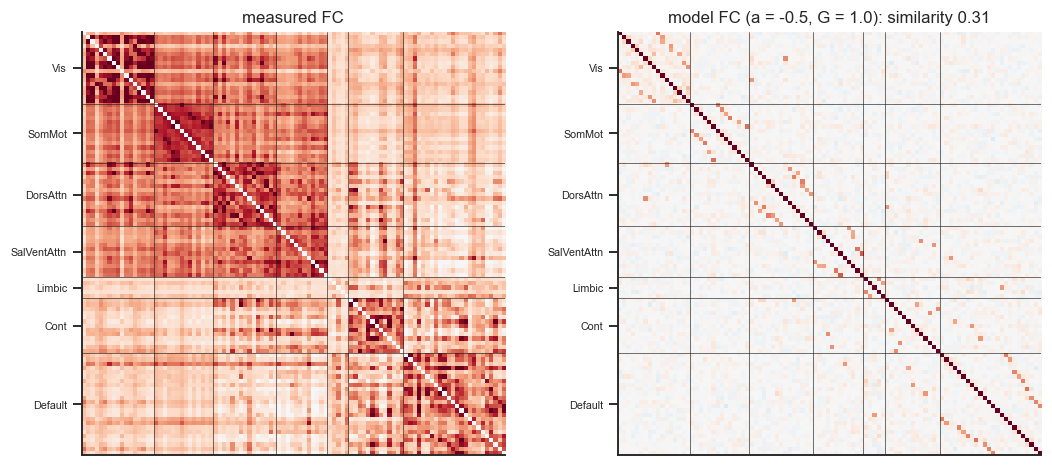

In [5]:
# your code: change a and G, then rerun
a, G = -0.5, 1.0
sim, M = fc_similarity(a, G)
fig, ax = plt.subplots(1, 2, figsize=(10, 4.4))
show_matrix(ax[0], fc, "measured FC", cmap="RdBu_r", vmin=-0.8, vmax=0.8)
show_matrix(ax[1], M, f"model FC (a = {a}, G = {G}): similarity {sim:.2f}", cmap="RdBu_r", vmin=-0.8, vmax=0.8)
plt.tight_layout(); plt.show()

Now let a loop do it: **complete `G_values`** (0 to about 8).

**Question 3.** Does stronger coupling always help? Is there a best $G$? Does it beat the wiring alone (0.32)?

G = 0.0: similarity 0.00


G = 1.0: similarity 0.31


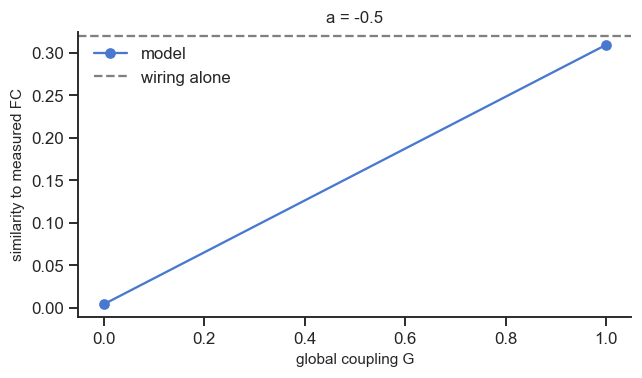

In [6]:
# your code: complete the list of couplings, e.g. 0, 0.25, 0.5, 1, 1.5, 2, 3, 4, 6, 8
a = -0.5
G_values = [0.0, 1.0]
scores = []
for G in G_values:
    s, _ = fc_similarity(a, G)
    scores.append(s); print(f"G = {G}: similarity {s:.2f}")

plt.figure(figsize=(6, 3.6))
plt.plot(G_values, scores, "o-", label="model"); plt.axhline(0.32, c="0.5", ls="--", label="wiring alone")
plt.xlabel("global coupling G"); plt.ylabel("similarity to measured FC"); plt.title(f"a = {a}"); plt.legend()
plt.tight_layout(); plt.show()

### Step 4. Both knobs

**Write a double loop** over $a$ (−1 to +0.3) and $G$ (0 to 8), store the similarities in a table (rows $a$,
columns $G$) and show it as an image. 10 × 10 combinations take about a minute.

**Question 4.** Where is the best fit, relative to the bifurcation ($a=0$)? What happens far below it, and beyond it?

**Question 5 (if time).** At $a=-1$ and its best $G$, increase the noise. Does the fit improve? Why (Question 2)?

<details><summary>Hint: the skeleton of a double loop</summary>

```python
a_list = [...]
G_list = [...]
table = np.zeros((len(a_list), len(G_list)))
for i, a in enumerate(a_list):
    for j, G in enumerate(G_list):
        table[i, j], _ = fc_similarity(a, G)
plt.imshow(table, origin="lower", aspect="auto")
plt.xticks(range(len(G_list)), G_list); plt.yticks(range(len(a_list)), a_list)
plt.xlabel("G"); plt.ylabel("a"); plt.colorbar(label="similarity"); plt.show()
```
</details>

In [7]:
# your code here

### Stuck? Explore with sliders

In [8]:
# @title Explore: distance to the bifurcation, coupling and noise
@interact(a=slider(-0.5, -1.0, 0.3, 0.02, "distance to bifurcation a"), G=slider(1.0, 0.0, 8.0, 0.25, "coupling G"),
          sigma=slider(0.02, 0.005, 0.1, 0.005, "noise σ"))
def explore_hopf_brain(a, G, sigma):
    sim, M = fc_similarity(a, G, sigma, runs=1); t, x = simulate(a, G, sigma, seed=0)
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1, 1]))
    for n, i in enumerate([2, 30, 85]): ax[0].plot(t[:150], x[:150, i] / x.std() + 4 * n, lw=1)
    ax[0].set(xlabel="time (s)", yticks=[], title=f"3 regions (size of fluctuations {x.std():.3f})")
    show_matrix(ax[1], M, "model FC", cmap="RdBu_r", vmin=-0.8, vmax=0.8)
    ax[2].plot(fc[u], M[u], ".", ms=1.5, c="0.4"); ax[2].set(xlabel="measured FC", ylabel="model FC", title=f"similarity {sim:.2f}")
    plt.tight_layout(); plt.show()

## 3. Solutions (look after the exercise)

Code hidden (click to show); results already computed.

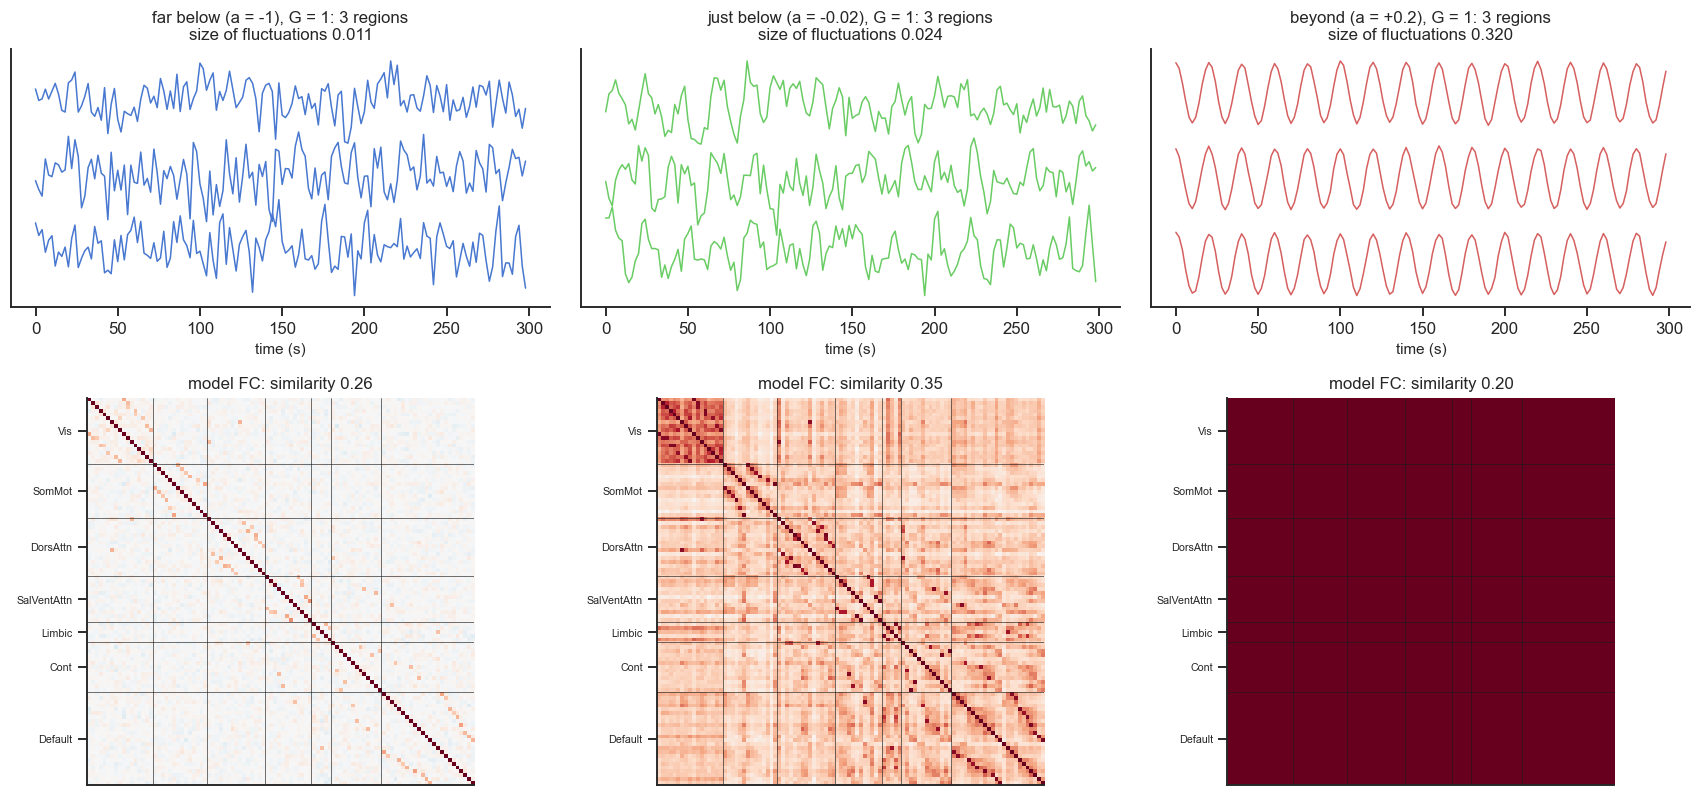

In [9]:
# @title Solution, steps 1-3: three distances to the bifurcation, same coupling
cases = [(-1.0, "far below (a = -1)", "C0"), (-0.02, "just below (a = -0.02)", "C2"), (0.2, "beyond (a = +0.2)", "C3")]
fig, ax = plt.subplots(2, 3, figsize=(16, 7.4), gridspec_kw=dict(height_ratios=[1, 1.5]))
for k, (a, name, c) in enumerate(cases):
    t, x = simulate(a, G=1.0)
    for n, i in enumerate([2, 30, 85]): ax[0, k].plot(t[:150], x[:150, i] / x.std() + 4 * n, c=c, lw=1)
    ax[0, k].set(title=f"{name}, G = 1: 3 regions\nsize of fluctuations {x.std():.3f}", xlabel="time (s)", yticks=[])
    sim, M = fc_similarity(a, 1.0)
    show_matrix(ax[1, k], M, f"model FC: similarity {sim:.2f}", cmap="RdBu_r", vmin=-0.8, vmax=0.8)
plt.tight_layout(); plt.show()

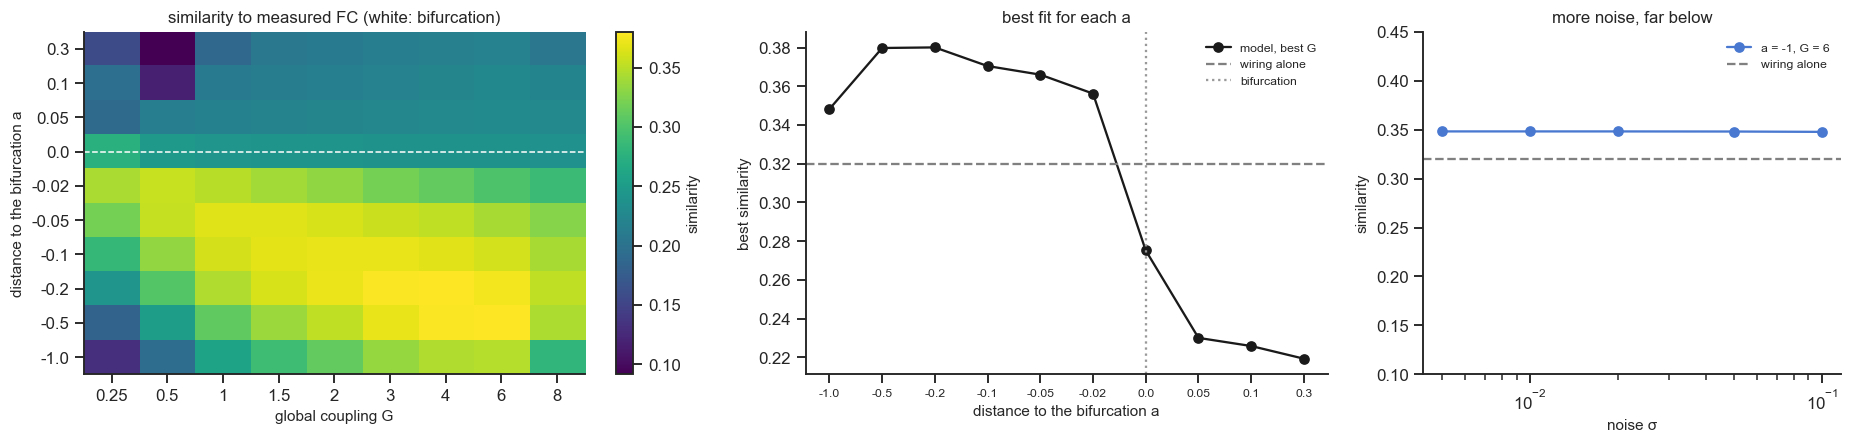

best: a = -0.2, G = 4, similarity 0.38;  at a = -1: 0.35;  at a = +0.3: 0.22


In [10]:
# @title Solution, steps 4-5: the full map of a and G, and more noise far from the bifurcation
a_list = [-1.0, -0.5, -0.2, -0.1, -0.05, -0.02, 0.0, 0.05, 0.1, 0.3]
G_list = [0.25, 0.5, 1, 1.5, 2, 3, 4, 6, 8]
table = np.array([[fc_similarity(a, G)[0] for G in G_list] for a in a_list])          # about 30 s
G_far = G_list[int(np.argmax(table[0]))]                                               # best G at a = -1
noises = [0.005, 0.01, 0.02, 0.05, 0.1]
noise_far = [fc_similarity(-1.0, G_far, sigma=s)[0] for s in noises]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw=dict(width_ratios=[1.2, 1, 0.8]))
im = ax[0].imshow(table, origin="lower", aspect="auto", cmap="viridis")
ax[0].set_xticks(range(len(G_list)), G_list); ax[0].set_yticks(range(len(a_list)), a_list)
ax[0].axhline(a_list.index(0.0), c="w", ls="--", lw=1)
ax[0].set(xlabel="global coupling G", ylabel="distance to the bifurcation a", title="similarity to measured FC (white: bifurcation)")
plt.colorbar(im, ax=ax[0], label="similarity")
ax[1].plot(range(len(a_list)), table.max(1), "ko-", label="model, best G"); ax[1].axhline(0.32, c="0.5", ls="--", label="wiring alone")
ax[1].axvline(a_list.index(0.0), c="0.6", ls=":", label="bifurcation"); ax[1].set_xticks(range(len(a_list)), a_list, fontsize=8)
ax[1].set(xlabel="distance to the bifurcation a", ylabel="best similarity", title="best fit for each a"); ax[1].legend(fontsize=8)
ax[2].plot(noises, noise_far, "o-", c="C0", label=f"a = -1, G = {G_far}"); ax[2].axhline(0.32, c="0.5", ls="--", label="wiring alone")
ax[2].set(xscale="log", ylim=(0.1, 0.45), xlabel="noise σ", ylabel="similarity", title="more noise, far below"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
i, j = np.unravel_index(np.argmax(table), table.shape)
print(f"best: a = {a_list[i]}, G = {G_list[j]}, similarity {table[i, j]:.2f};  at a = -1: {table[0].max():.2f};  at a = +0.3: {table[-1].max():.2f}")

<details><summary>Discussion (open after the exercise)</summary>

1. **One region.** Far below the bifurcation: fast jitter, every push is forgotten in about a second. Beyond it: a
   regular clock. Just below: slow, irregular waves that come and go, like real BOLD (critical slowing down, NB08).
2. **Noise.** Below the bifurcation the model is almost **linear**: noise scales the signal but does not change its
   shape. Above it the rhythm sets the size, and noise barely matters.
3. **Coupling.** There is a best $G$: too weak and regions ignore each other, too strong and they all move together.
4. **The map.** The best fit is a band **below the bifurcation, not far from it**. Far below, the fit is lower and
   needs strong coupling. From $a=0$ upwards it collapses: every region is a clock, they lock, the wiring no longer
   shows.
5. **Noise does not rescue** a region far from the bifurcation: in a linear system the correlations do not depend on how
   loud the noise is.

Near the bifurcation a region amplifies and prolongs its inputs, so activity travels along the connectome and builds
large-scale patterns (Deco et al. 2017). Average FC allows a broad band of $a$; NB13 adds a harder target, dynamic FC.
</details>

## 4. Take-home

* A whole-brain model = **a model per region** + **connectome** + **global coupling $G$** + **noise**, compared with data.
* The model beats the wiring alone: dynamics carry correlations along indirect paths.
* Best fit: regions **below their Hopf bifurcation, not far from it**. Far below, noise does not help; beyond, regions
  lock and the fit collapses.
* **Next (NB13):** the same search, pre-run on a finer grid, and a second target: dynamic FC.

### Homework
*To do at home, after the class.*
1. **No connectome.** Replace `sc` by a matrix with the same weights in random positions (shuffle the upper triangle,
   then symmetrise). How much of the best fit survives?
2. **No mirror connections.** Load the connectome with `homotopic=0`. What happens to the correlations between the two
   hemispheres, and to the best fit?
3. **Different regions.** Give each region its own frequency `f` (a vector, e.g. between 0.04 and 0.07 Hz). Does the
   best working point move?

### References
* Deco G, Kringelbach ML, Jirsa VK, Ritter P (2017). The dynamics of resting fluctuations in the brain: metastability
  and its dynamical cortical core. *Sci Rep* 7:3095.
* Honey CJ et al. (2009). Predicting human resting-state functional connectivity from structural connectivity.
  *PNAS* 106:2035–2040.
* Larivière S et al. (2021). The ENIGMA Toolbox. *Nat Methods* 18:698–700. (Connectome and FC.)
* Richardson H et al. (2018). Development of the social brain from age three to twelve years. *Nat Commun* 9:1027.
  (OpenNeuro ds000228: the BOLD trace of step 1.)